In [30]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [31]:
import json
from pathlib import Path

import dask
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr

sns.set_style("whitegrid", {"grid.color": ".93"})

In [32]:
all_chains = [
    "MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH",
    "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES",
    "MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5",
    "MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR",
    "MOHC-HadREM3-GA7-05_NCC-NorESM1-M",
    "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5",
    "CNRM-ALADIN63_NCC-NorESM1-M",
    "CNRM-ALADIN63_MPI-M-MPI-ESM-LR",
    "CNRM-ALADIN63_MOHC-HadGEM2-ES",
]

# Functions

In [33]:
CHAIN_LABELS = {
    c: c.replace("MOHC-HadREM3-GA7-05_", "HadREM3/").replace(
        "CNRM-ALADIN63_", "ALADIN63/"
    )
    for c in all_chains
}
COLORS = plt.cm.tab10(np.linspace(0, 1, len(all_chains)))


def plot_per_model(annual_data, countries, variable_label, unit="GWh/year"):
    """Per-country subplots, one line per model chain."""
    ncols = 3
    nrows = int(np.ceil(len(countries) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4 * nrows), sharex=True)
    axes = axes.flatten()

    for ax, country in zip(axes, countries):
        for (chain, df), color in zip(annual_data.items(), COLORS):
            if country not in df.columns:
                continue
            ax.plot(
                df.index,
                df[country],
                linewidth=0.8,
                color=color,
                label=CHAIN_LABELS[chain],
                alpha=0.85,
            )
        ax.set_title(country, fontsize=9, fontweight="bold")
        ax.set_ylabel(unit, fontsize=8)
        ax.yaxis.grid(True, linewidth=0.3)
        ax.set_axisbelow(True)

    for ax in axes[len(countries) :]:
        ax.set_visible(False)

    # Single shared legend outside the grid
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=5,
        fontsize=8,
        bbox_to_anchor=(0.5, -0.03),
        frameon=True,
    )
    fig.suptitle(f"{variable_label} — annual totals per model chain", fontsize=12)
    plt.tight_layout()
    plt.show()


def plot_multimodel(annual_data, countries, variable_label, unit="GWh/year"):
    """Per-country subplots: multi-model mean + min–max spread."""
    ncols = 3
    nrows = int(np.ceil(len(countries) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4 * nrows), sharex=True)
    axes = axes.flatten()

    for ax, country in zip(axes, countries):
        # Stack all chains for this country into a single DataFrame (year × chain)
        frames = {
            CHAIN_LABELS[c]: df[country]
            for c, df in annual_data.items()
            if country in df.columns
        }
        stacked = pd.DataFrame(frames)

        mm_mean = stacked.mean(axis=1)
        mm_min = stacked.min(axis=1)
        mm_max = stacked.max(axis=1)

        ax.fill_between(
            stacked.index,
            mm_min,
            mm_max,
            color="steelblue",
            alpha=0.25,
            label="model range",
        )
        ax.plot(
            stacked.index,
            mm_mean,
            color="steelblue",
            linewidth=1.5,
            label="multi-model mean",
        )

        ax.set_title(country, fontsize=9, fontweight="bold")
        ax.set_ylabel(unit, fontsize=8)
        ax.yaxis.grid(True, linewidth=0.3)
        ax.set_axisbelow(True)
        ax.legend(fontsize=7, loc="upper right")

    for ax in axes[len(countries) :]:
        ax.set_visible(False)

    fig.suptitle(
        f"{variable_label} — multi-model mean ± range (annual totals)", fontsize=12
    )
    plt.tight_layout()
    plt.show()

# Hydropower

## RoR

In [34]:
df_old = pd.read_csv(
    "/net/xenon/climphys/lbloin/CESM2energy/output/CORDEX_data/MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH/output_variables/hydro_ror_CORDEX_MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_1991-1995_85.csv"
)
df_new = pd.read_csv(
    "/net/exo/landclim/yhaddad/clim2energy-ch/c2e/outputs/MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH/output_variables/hydro_ror_CORDEX_MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_85.csv"
)

In [35]:
df_old

,country,1991-01-01 12:00:00,1991-01-02 12:00:00,1991-01-03 12:00:00,1991-01-04 12:00:00,1991-01-05 12:00:00,1991-01-06 12:00:00,1991-01-07 12:00:00,1991-01-08 12:00:00,1991-01-09 12:00:00,...,1995-12-22 12:00:00,1995-12-23 12:00:00,1995-12-24 12:00:00,1995-12-25 12:00:00,1995-12-26 12:00:00,1995-12-27 12:00:00,1995-12-28 12:00:00,1995-12-29 12:00:00,1995-12-30 12:00:00,1995-12-31 12:00:00
0,Austria,66.194507,67.208641,68.063918,67.976973,66.702317,64.735546,62.518888,60.298462,58.316941,...,49.032082,47.955129,47.218907,46.838263,46.740235,46.838212,47.081835,47.434608,47.804780,48.030298
1,Switzerland,2.306755,2.263641,2.184619,2.112143,2.044810,1.977872,1.910813,1.882514,1.907239,...,3.263265,3.231010,3.204183,3.180240,3.156606,3.135362,3.107394,3.069613,3.037530,3.007411
2,Spain,28.711714,28.464103,28.228303,27.977847,27.700488,27.389640,27.063314,26.753192,26.544720,...,13.524242,13.798560,14.112771,14.479755,14.784281,15.001950,15.012039,15.291770,15.865041,16.588372
3,Italy,44.759881,44.743640,44.998851,45.252584,46.275882,47.519198,47.829984,47.748738,47.645157,...,49.492998,49.244468,49.401883,49.580636,48.314642,46.615239,45.823375,44.320721,42.345788,39.776129
4,France,148.963812,150.737729,150.966085,149.518242,147.715863,145.277796,142.622749,140.055377,138.297349,...,150.966085,150.966085,150.966085,150.966085,150.966085,150.966085,150.966085,150.966085,150.966085,150.966085
5,Germany,28.864763,29.257463,28.879634,28.208883,27.401708,26.587017,25.803600,25.249700,25.142597,...,30.573624,30.341585,30.235523,30.202887,30.222676,30.288370,30.305512,30.208136,29.987017,29.606158


In [36]:
df_new

,country,1991-01-01 12:00:00,1991-01-02 12:00:00,1991-01-03 12:00:00,1991-01-04 12:00:00,1991-01-05 12:00:00,1991-01-06 12:00:00,1991-01-07 12:00:00,1991-01-08 12:00:00,1991-01-09 12:00:00,...,2099-12-22 12:00:00,2099-12-23 12:00:00,2099-12-24 12:00:00,2099-12-25 12:00:00,2099-12-26 12:00:00,2099-12-27 12:00:00,2099-12-28 12:00:00,2099-12-29 12:00:00,2099-12-30 12:00:00,2099-12-31 12:00:00
0,Austria,66.194507,67.208641,68.063918,67.976973,66.702317,64.735546,62.518888,60.298462,58.316941,...,22.570472,20.853367,19.249404,17.903215,16.649848,15.282787,13.853083,12.639062,11.757622,11.213914
1,Germany,28.864763,29.257463,28.879634,28.208883,27.401708,26.587017,25.803600,25.249700,25.142597,...,10.379492,9.602759,8.804910,8.093501,7.526185,7.060393,6.697938,6.498615,6.422395,6.423099
2,Spain,28.711714,28.464103,28.228303,27.977847,27.700488,27.389640,27.063314,26.753192,26.544720,...,11.552394,11.768391,12.041207,12.351672,12.732459,13.181554,13.701139,14.309891,14.758603,15.483547
3,Switzerland,23.005518,22.575539,21.787442,21.064634,20.393121,19.725534,19.056753,18.774525,19.021101,...,12.478789,11.838202,10.914023,9.961372,9.385140,9.024149,8.707458,8.511620,8.430223,8.404997
4,France,148.963812,150.737729,150.966085,149.518242,147.715863,145.277796,142.622749,140.055377,138.297349,...,93.343834,86.130947,80.260612,74.969450,69.933721,65.458327,62.214402,60.263037,59.268438,58.859154
5,Italy,44.759881,44.743640,44.998851,45.252584,46.275882,47.519198,47.829984,47.748738,47.645157,...,60.198714,52.457072,41.112079,36.431020,34.736350,34.008634,33.621979,33.347994,33.109179,32.927693


In [37]:
# Reshape from wide to long (dates as columns → dates as index)
def wide_to_long(df):
    # Support both: DataFrame with 'country' column, or DataFrame already indexed by country
    if "country" in df.columns:
        df = df.set_index("country")
    df = df.T
    df.index = pd.to_datetime(df.index)
    df.index.name = "time"
    return df


ts_old = wide_to_long(df_old)
ts_new = wide_to_long(df_new)

print("OLD:", ts_old.index.min(), "→", ts_old.index.max(), f"({len(ts_old)} steps)")
print("NEW:", ts_new.index.min(), "→", ts_new.index.max(), f"({len(ts_new)} steps)")

OLD: 1991-01-01 12:00:00 → 1995-12-31 12:00:00 (1825 steps)
NEW: 1991-01-01 12:00:00 → 2099-12-31 12:00:00 (39785 steps)


In [38]:
# Find common timeframe and align
common_idx = ts_old.index.intersection(ts_new.index)
common_countries = ts_old.columns.intersection(ts_new.columns)

ts_old_c = ts_old.loc[common_idx, common_countries]
ts_new_c = ts_new.loc[common_idx, common_countries]

print(
    f"Common period : {common_idx.min().date()} → {common_idx.max().date()}  ({len(common_idx)} days)"
)
print(f"Common countries ({len(common_countries)}): {common_countries.tolist()}")

Common period : 1991-01-01 → 1995-12-31  (1825 days)
Common countries (6): ['Austria', 'Switzerland', 'Spain', 'Italy', 'France', 'Germany']


In [39]:
# Summary statistics comparison over the common period
diff = ts_new_c - ts_old_c
rel_diff = (diff / ts_old_c.replace(0, np.nan)) * 100  # percent difference

stats = pd.DataFrame(
    {
        "old_mean": ts_old_c.mean(),
        "new_mean": ts_new_c.mean(),
        "bias": diff.mean(),
        "bias_%": rel_diff.mean(),
        "rmse": np.sqrt((diff**2).mean()),
        "corr": ts_old_c.corrwith(ts_new_c),
    }
).round(4)

print(stats.to_string())

             old_mean  new_mean     bias    bias_%     rmse    corr
country                                                            
Austria       75.0645   75.0477  -0.0167   -0.0353   0.2553  0.9999
Switzerland    4.5689   45.5965  41.0276  897.5531  44.2338  0.9999
Spain         23.3924   23.3847  -0.0077   -0.0497   0.1271  0.9999
Italy         78.0280   78.0057  -0.0223   -0.0493   0.3280  1.0000
France       119.5425  119.5377  -0.0048   -0.0032   0.1712  1.0000
Germany       38.5076   38.4970  -0.0106   -0.0352   0.1592  0.9999


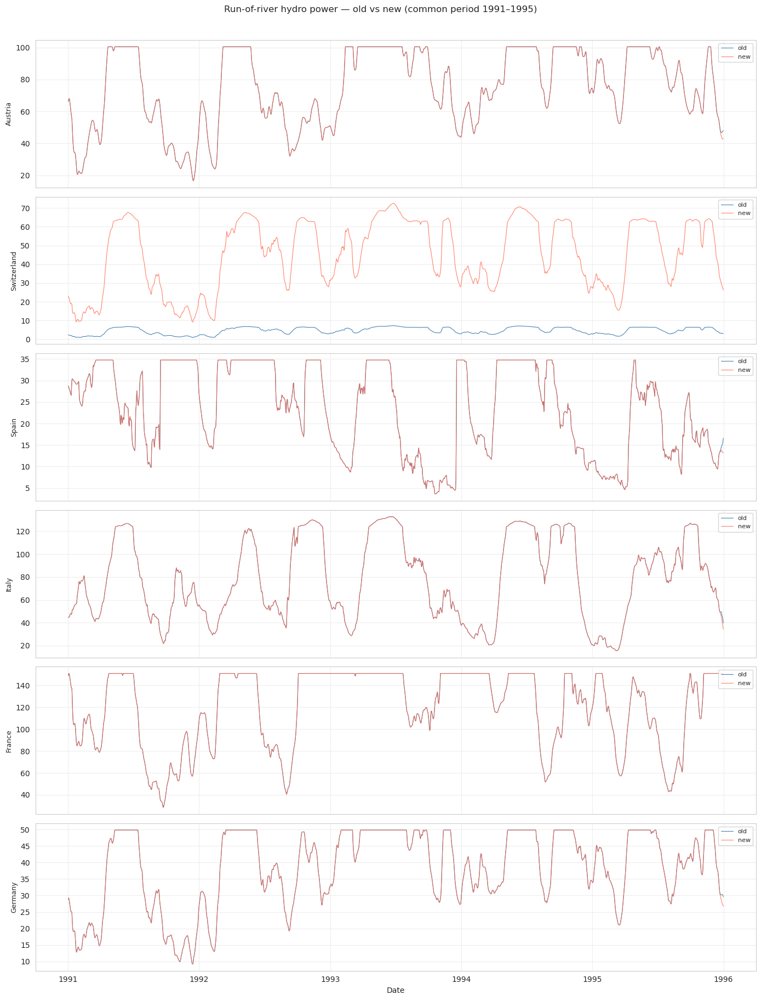

In [40]:
# Time-series comparison: one panel per country
n_countries = len(common_countries)
fig, axes = plt.subplots(n_countries, 1, figsize=(14, 3 * n_countries), sharex=True)

for ax, country in zip(axes, common_countries):
    ax.plot(
        ts_old_c.index, ts_old_c[country], label="old", linewidth=0.8, color="steelblue"
    )
    ax.plot(
        ts_new_c.index,
        ts_new_c[country],
        label="new",
        linewidth=0.8,
        color="tomato",
        alpha=0.8,
    )
    ax.set_ylabel(country, fontsize=9)
    ax.legend(loc="upper right", fontsize=8)

axes[-1].set_xlabel("Date")
fig.suptitle("Run-of-river hydro power — old vs new (common period 1991–1995)", y=1.01)
plt.tight_layout()
plt.show()

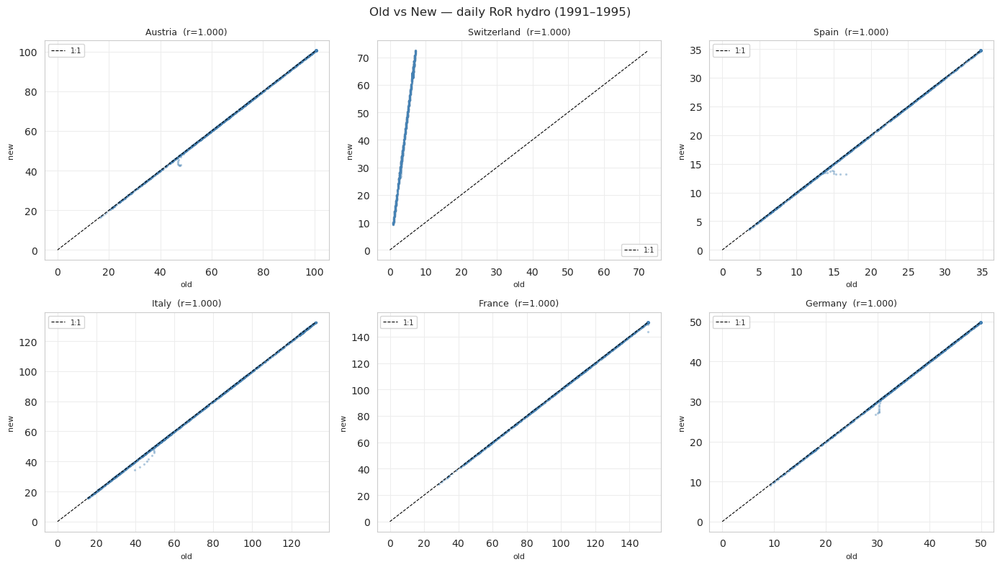

In [41]:
# Scatter plots: old vs new per country
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for ax, country in zip(axes, common_countries):
    x = ts_old_c[country].values
    y = ts_new_c[country].values
    ax.scatter(x, y, s=2, alpha=0.3, color="steelblue")
    lim = max(np.nanmax(x), np.nanmax(y))
    ax.plot([0, lim], [0, lim], "k--", linewidth=0.8, label="1:1")
    corr = np.corrcoef(x[~np.isnan(x) & ~np.isnan(y)], y[~np.isnan(x) & ~np.isnan(y)])[
        0, 1
    ]
    ax.set_title(f"{country}  (r={corr:.3f})", fontsize=9)
    ax.set_xlabel("old", fontsize=8)
    ax.set_ylabel("new", fontsize=8)
    ax.legend(fontsize=7)

fig.suptitle("Old vs New — daily RoR hydro (1991–1995)")
plt.tight_layout()
plt.show()

## Inflow

In [42]:
paths_old = sorted(
    Path(
        "/net/xenon/climphys/lbloin/CESM2energy/output/CORDEX_data/MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH/output_variables/"
    ).glob("hydro_inflow_CORDEX_MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_*_85.csv")
)
df_old = pd.concat(
    [pd.read_csv(path).set_index("country") for path in paths_old],
    axis=1,
)

df_new = pd.read_csv(
    "/net/exo/landclim/yhaddad/clim2energy-ch/c2e/outputs/MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH/output_variables/hydro_inflow_CORDEX_MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_85.csv"
)

In [43]:
ds_entsoe = xr.open_dataset(
    "/net/xenon/climphys/lbloin/CESM2energy/inputs/entsoe_inflow/entsoe_inflow.nc"
)

In [44]:
# Reshape from wide to long
ts_old = wide_to_long(df_old)
ts_new = wide_to_long(df_new)

# Common timeframe
common_idx = ts_old.index.intersection(ts_new.index)
common_countries = ts_old.columns.intersection(ts_new.columns)

ts_old_c = ts_old.loc[common_idx, common_countries]
ts_new_c = ts_new.loc[common_idx, common_countries]

print(
    f"Common period : {common_idx.min().date()} → {common_idx.max().date()}  ({len(common_idx)} days)"
)
print(f"Common countries ({len(common_countries)}): {common_countries.tolist()}")

Common period : 1990-12-31 → 2060-12-27  (3653 days)
Common countries (10): ['Austria', 'Bulgaria', 'Switzerland', 'Spain', 'France', 'Italy', 'Norway', 'Portugal', 'Romania', 'Sweden']


In [45]:
# Summary statistics
diff = ts_new_c - ts_old_c
rel_diff = (diff / ts_old_c.replace(0, np.nan)) * 100

stats = pd.DataFrame(
    {
        "old_mean": ts_old_c.mean(),
        "new_mean": ts_new_c.mean(),
        "bias": diff.mean(),
        "bias_%": rel_diff.mean(),
        "rmse": np.sqrt((diff**2).mean()),
        "corr": ts_old_c.corrwith(ts_new_c),
    }
).round(4)

print(stats.to_string())

              old_mean   new_mean      bias   bias_%      rmse    corr
country                                                               
Austria        95.7785    96.0414    0.0557   0.4815    0.7704  0.9999
Bulgaria       52.1996    52.3314    0.1518   0.5405    2.1543  0.9982
Switzerland   193.6923   343.1321  148.6113  79.7063  201.9945  0.9993
Spain         424.3667   424.6382    1.5648   0.3586   23.1955  0.9980
France        287.1820   287.5921    0.7059   0.2767    8.9706  0.9981
Italy         115.6787   115.9584    0.1568   0.4015    2.1738  0.9995
Norway       2391.5123  2398.4403    5.0618   0.7012   55.6562  0.9995
Portugal       62.5423    62.6035    0.3316   0.4862    5.2663  0.9970
Romania       127.0497   127.3234    0.2600   0.2954    2.9247  0.9983
Sweden       1398.6917  1402.1939    1.7187   0.3359   19.8047  0.9998


In [46]:
# --- Mean weekly inflow per country: df_old, df_new, ENTSOE ---

# df_old is already weekly — reshape and slice
ts_old_full = wide_to_long(df_old)
ts_old_sel = ts_old_full.loc["1995":"2023"]

# df_new is daily — reshape, slice, resample to weekly sums
ts_new_full = wide_to_long(df_new)
ts_new_sel = ts_new_full.resample("W").sum().loc["1995":"2023"]

# ENTSOE: convert xarray to DataFrame (already weekly, time × country)
ts_entsoe = ds_entsoe["inflow_GWh"].to_pandas().T
ts_entsoe.index.name = "time"

# Mean weekly inflow per country
mean_old = ts_old_sel.mean()
mean_new = ts_new_sel.mean()
mean_entsoe = ts_entsoe.mean()

# Common countries across all three
common = (
    mean_old.index.intersection(mean_new.index)
    .intersection(mean_entsoe.index)
    .sort_values()
)

df_means = pd.DataFrame(
    {
        "old (1995–2023)": mean_old[common],
        "new (1995–2023)": mean_new[common],
        "ENTSOE (2016–2023)": mean_entsoe[common],
    }
)
print(df_means.round(1).to_string())

             old (1995–2023)  new (1995–2023)  ENTSOE (2016–2023)
country                                                          
Austria                 89.5             89.7                96.5
Bulgaria                49.7             49.8                49.7
France                 271.8            272.1               292.2
Italy                  111.4            111.6               129.1
Norway                2271.0           2276.8              2417.7
Portugal                63.3             63.4                57.3
Romania                119.5            119.7               123.3
Spain                  435.0            435.1               418.5
Sweden                1286.3           1288.9              1345.3
Switzerland            184.7            327.9               223.6


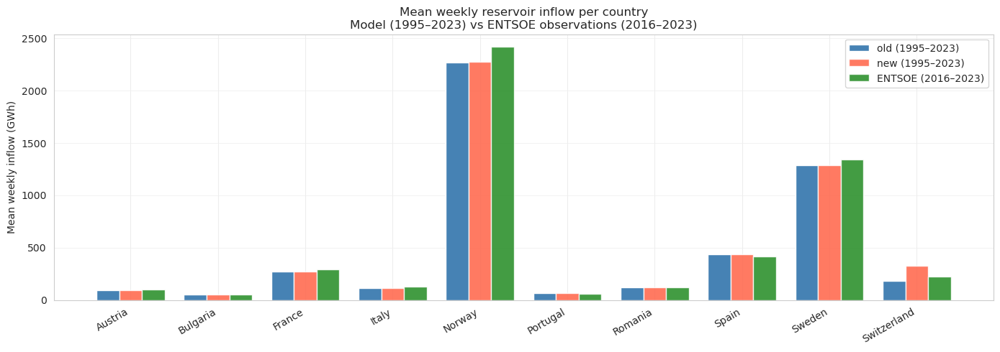

In [47]:
# Bar plot: mean weekly inflow per country — old vs new vs ENTSOE
x = np.arange(len(common))
width = 0.26

fig, ax = plt.subplots(figsize=(14, 5))

bars_old = ax.bar(
    x - width,
    df_means["old (1995–2023)"],
    width,
    label="old (1995–2023)",
    color="steelblue",
)
bars_new = ax.bar(
    x,
    df_means["new (1995–2023)"],
    width,
    label="new (1995–2023)",
    color="tomato",
    alpha=0.85,
)
bars_entsoe = ax.bar(
    x + width,
    df_means["ENTSOE (2016–2023)"],
    width,
    label="ENTSOE (2016–2023)",
    color="forestgreen",
    alpha=0.85,
)

ax.set_xticks(x)
ax.set_xticklabels(common, rotation=30, ha="right")
ax.set_ylabel("Mean weekly inflow (GWh)")
ax.set_title(
    "Mean weekly reservoir inflow per country\nModel (1995–2023) vs ENTSOE observations (2016–2023)"
)
ax.legend()
ax.yaxis.grid(True, linewidth=0.5)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## All chains — Inflow comparison (old vs new vs ENTSOE)


In [22]:
OLD_BASE = Path("/net/xenon/climphys/lbloin/CESM2energy/output/CORDEX_data")
NEW_BASE = Path("/net/exo/landclim/yhaddad/clim2energy-ch/c2e/outputs")


def load_chain_inflow(chain):
    """Load old (weekly, multi-file) and new (daily) inflow CSVs for a given chain.
    Returns (ts_old_weekly, ts_new_weekly) as DataFrames indexed by time, or None if files are missing.
    """
    old_paths = sorted(
        (OLD_BASE / chain / "output_variables").glob(
            f"hydro_inflow_CORDEX_{chain}_*_85.csv"
        )
    )
    new_path = (
        NEW_BASE / chain / "output_variables" / f"hydro_inflow_CORDEX_{chain}_85.csv"
    )

    if not old_paths or not new_path.exists():
        return None, None

    df_old = pd.concat([pd.read_csv(p).set_index("country") for p in old_paths], axis=1)
    df_new = pd.read_csv(new_path)

    ts_old = wide_to_long(df_old)  # already weekly (Monday-anchored)
    ts_new = (
        wide_to_long(df_new).resample("W-MON").sum()
    )  # daily → weekly sums, Monday anchor

    return ts_old, ts_new


# ENTSOE reference (already in kernel, just re-expose as weekly DataFrame)
ts_entsoe = ds_entsoe["inflow_GWh"].to_pandas().T
ts_entsoe.index.name = "time"

# Load all chains
chain_data = {}
for chain in all_chains:
    ts_old, ts_new = load_chain_inflow(chain)
    if ts_old is None:
        print(f"  SKIP {chain} — old file missing")
    else:
        chain_data[chain] = {"old": ts_old, "new": ts_new}
        print(f"  OK   {chain}")

print(f"\nLoaded {len(chain_data)}/{len(all_chains)} chains.")

  OK   MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH
  OK   MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES
  OK   MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5
  OK   MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR
  OK   MOHC-HadREM3-GA7-05_NCC-NorESM1-M
  OK   CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5
  OK   CNRM-ALADIN63_NCC-NorESM1-M
  OK   CNRM-ALADIN63_MPI-M-MPI-ESM-LR
  OK   CNRM-ALADIN63_MOHC-HadGEM2-ES

Loaded 9/9 chains.


In [23]:
# Per-chain summary statistics: old vs new (1995–2023 common window)
all_stats = {}

for chain, data in chain_data.items():
    ts_o = data["old"].loc["1995":"2023"]
    ts_n = data["new"].loc["1995":"2023"]

    common_idx = ts_o.index.intersection(ts_n.index)
    common_countries = ts_o.columns.intersection(ts_n.columns).sort_values()

    ts_o = ts_o.loc[common_idx, common_countries]
    ts_n = ts_n.loc[common_idx, common_countries]

    diff = ts_n - ts_o
    rel_diff = (diff / ts_o.replace(0, np.nan)) * 100

    stats = pd.DataFrame(
        {
            "old_mean": ts_o.mean(),
            "new_mean": ts_n.mean(),
            "bias": diff.mean(),
            "bias_%": rel_diff.mean(),
            "rmse": np.sqrt((diff**2).mean()),
            "corr": ts_o.corrwith(ts_n),
        }
    ).round(3)
    all_stats[chain] = stats

# Display per chain
for chain, stats in all_stats.items():
    print(f"\n{'─'*60}")
    print(f"  {chain}")
    print(f"{'─'*60}")
    print(stats.to_string())


────────────────────────────────────────────────────────────
  MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH
────────────────────────────────────────────────────────────
             old_mean  new_mean      bias   bias_%      rmse   corr
country                                                            
Austria        89.497   113.870    24.132   86.587    56.497  0.942
Bulgaria       49.747    60.099    10.373   12.051    25.431  0.950
France        271.767   697.826   427.303  148.213   518.029  0.960
Italy         111.412   155.980    44.355   31.794    79.150  0.939
Norway       2271.011  4979.651  2703.880  154.095  3171.498  0.994
Portugal       63.324   250.295   188.157  432.560   304.141  0.985
Romania       119.468   300.687   181.258  143.793   213.422  0.953
Spain         434.958  1758.378  1330.885  256.031  2108.752  0.958
Sweden       1286.303  1871.150   581.903   38.209   853.050  0.995
Switzerland   184.695   528.911   342.921  138.307   630.226  0.935

───────────────────────

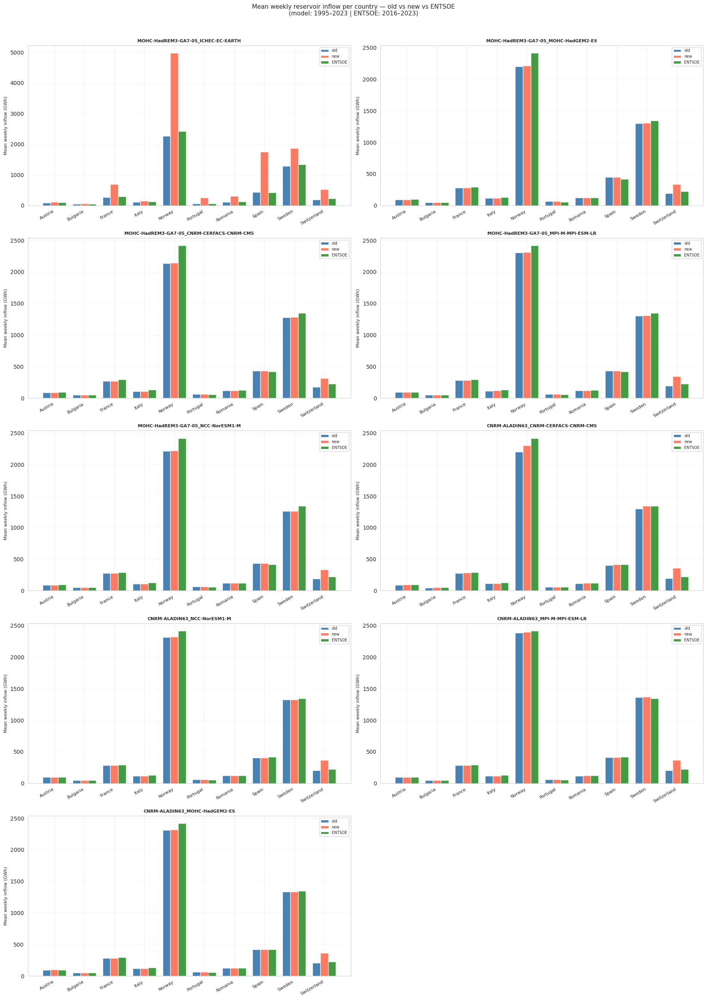

In [24]:
# Per-chain bar plots: mean weekly inflow — old vs new vs ENTSOE
mean_entsoe = ts_entsoe.mean()

n_chains = len(chain_data)
ncols_fig = 2
nrows_fig = int(np.ceil(n_chains / ncols_fig))

fig, axes = plt.subplots(
    nrows_fig, ncols_fig, figsize=(18, 5 * nrows_fig), sharey=False
)
axes = axes.flatten()

for ax, (chain, data) in zip(axes, chain_data.items()):
    ts_o = data["old"].loc["1995":"2023"]
    ts_n = data["new"].loc["1995":"2023"]

    common_countries = (
        ts_o.columns.intersection(ts_n.columns)
        .intersection(mean_entsoe.index)
        .sort_values()
    )

    mean_old = ts_o[common_countries].mean()
    mean_new = ts_n[common_countries].mean()

    x = np.arange(len(common_countries))
    width = 0.26

    ax.bar(x - width, mean_old, width, label="old", color="steelblue")
    ax.bar(x, mean_new, width, label="new", color="tomato", alpha=0.85)
    ax.bar(
        x + width,
        mean_entsoe[common_countries],
        width,
        label="ENTSOE",
        color="forestgreen",
        alpha=0.85,
    )

    ax.set_xticks(x)
    ax.set_xticklabels(common_countries, rotation=30, ha="right", fontsize=8)
    ax.set_ylabel("Mean weekly inflow (GWh)", fontsize=8)
    ax.set_title(chain, fontsize=8, fontweight="bold")
    ax.legend(fontsize=7)
    ax.yaxis.grid(True, linewidth=0.4)
    ax.set_axisbelow(True)

# Hide unused subplot panels
for ax in axes[n_chains:]:
    ax.set_visible(False)

fig.suptitle(
    "Mean weekly reservoir inflow per country — old vs new vs ENTSOE\n(model: 1995–2023 | ENTSOE: 2016–2023)",
    y=1.01,
    fontsize=11,
)
plt.tight_layout()
plt.show()

## Analysis of new simulations

In [25]:
# Load all new RoR and inflow files, aggregate to annual sums per country
NEW_BASE = Path("/net/exo/landclim/yhaddad/clim2energy-ch/c2e/outputs")

CHAIN_LABELS = {
    c: c.replace("MOHC-HadREM3-GA7-05_", "HadREM3/").replace(
        "CNRM-ALADIN63_", "ALADIN63/"
    )
    for c in all_chains
}
COLORS = plt.cm.tab10(np.linspace(0, 1, len(all_chains)))

ror_annual = {}  # {chain: DataFrame(year × country)}
inflow_annual = {}  # {chain: DataFrame(year × country)}

for chain in all_chains:
    out = NEW_BASE / chain / "output_variables"

    ror_path = out / f"hydro_ror_CORDEX_{chain}_85.csv"
    if ror_path.exists():
        ts = wide_to_long(pd.read_csv(ror_path))
        ror_annual[chain] = ts.groupby(ts.index.year).sum()

    inf_path = out / f"hydro_inflow_CORDEX_{chain}_85.csv"
    if inf_path.exists():
        ts = wide_to_long(pd.read_csv(inf_path))
        inflow_annual[chain] = ts.groupby(ts.index.year).sum()

print(f"RoR    : {len(ror_annual)}/{len(all_chains)} chains loaded")
print(f"Inflow : {len(inflow_annual)}/{len(all_chains)} chains loaded")

ror_countries = sorted(set.intersection(*[set(v.columns) for v in ror_annual.values()]))
inflow_countries = sorted(
    set.intersection(*[set(v.columns) for v in inflow_annual.values()])
)
print(f"\nRoR    countries ({len(ror_countries)}): {ror_countries}")
print(f"Inflow countries ({len(inflow_countries)}): {inflow_countries}")

RoR    : 9/9 chains loaded
Inflow : 9/9 chains loaded

RoR    countries (6): ['Austria', 'France', 'Germany', 'Italy', 'Spain', 'Switzerland']
Inflow countries (10): ['Austria', 'Bulgaria', 'France', 'Italy', 'Norway', 'Portugal', 'Romania', 'Spain', 'Sweden', 'Switzerland']


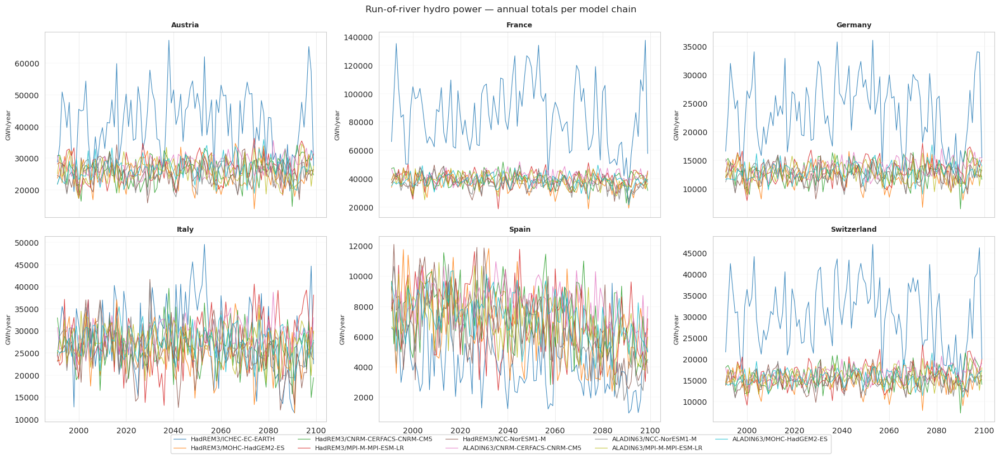

In [26]:
def plot_per_model(annual_data, countries, variable_label, unit="GWh/year"):
    """Per-country subplots, one line per model chain."""
    ncols = 3
    nrows = int(np.ceil(len(countries) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4 * nrows), sharex=True)
    axes = axes.flatten()

    for ax, country in zip(axes, countries):
        for (chain, df), color in zip(annual_data.items(), COLORS):
            if country not in df.columns:
                continue
            ax.plot(
                df.index,
                df[country],
                linewidth=0.8,
                color=color,
                label=CHAIN_LABELS[chain],
                alpha=0.85,
            )
        ax.set_title(country, fontsize=9, fontweight="bold")
        ax.set_ylabel(unit, fontsize=8)
        ax.yaxis.grid(True, linewidth=0.3)
        ax.set_axisbelow(True)

    for ax in axes[len(countries) :]:
        ax.set_visible(False)

    # Single shared legend outside the grid
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=5,
        fontsize=8,
        bbox_to_anchor=(0.5, -0.03),
        frameon=True,
    )
    fig.suptitle(f"{variable_label} — annual totals per model chain", fontsize=12)
    plt.tight_layout()
    plt.show()


plot_per_model(ror_annual, ror_countries, "Run-of-river hydro power")

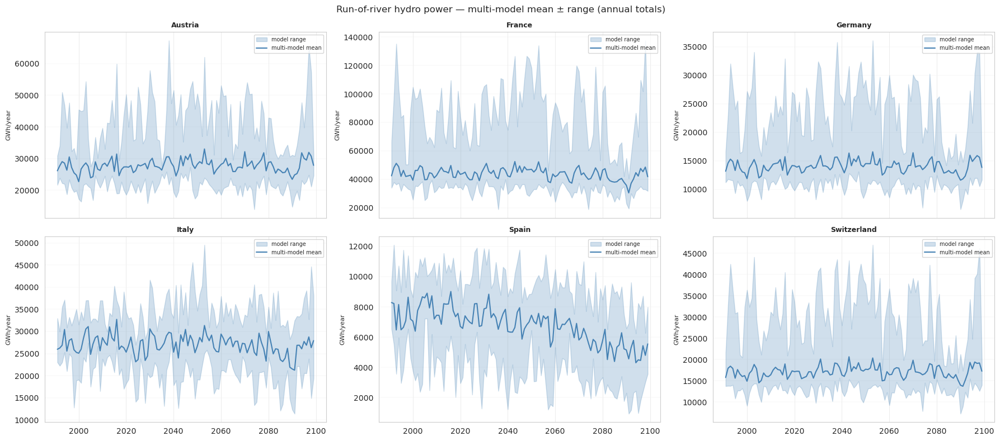

In [27]:
def plot_multimodel(annual_data, countries, variable_label, unit="GWh/year"):
    """Per-country subplots: multi-model mean + min–max spread."""
    ncols = 3
    nrows = int(np.ceil(len(countries) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4 * nrows), sharex=True)
    axes = axes.flatten()

    for ax, country in zip(axes, countries):
        # Stack all chains for this country into a single DataFrame (year × chain)
        frames = {
            CHAIN_LABELS[c]: df[country]
            for c, df in annual_data.items()
            if country in df.columns
        }
        stacked = pd.DataFrame(frames)

        mm_mean = stacked.mean(axis=1)
        mm_min = stacked.min(axis=1)
        mm_max = stacked.max(axis=1)

        ax.fill_between(
            stacked.index,
            mm_min,
            mm_max,
            color="steelblue",
            alpha=0.25,
            label="model range",
        )
        ax.plot(
            stacked.index,
            mm_mean,
            color="steelblue",
            linewidth=1.5,
            label="multi-model mean",
        )

        ax.set_title(country, fontsize=9, fontweight="bold")
        ax.set_ylabel(unit, fontsize=8)
        ax.yaxis.grid(True, linewidth=0.3)
        ax.set_axisbelow(True)
        ax.legend(fontsize=7, loc="upper right")

    for ax in axes[len(countries) :]:
        ax.set_visible(False)

    fig.suptitle(
        f"{variable_label} — multi-model mean ± range (annual totals)", fontsize=12
    )
    plt.tight_layout()
    plt.show()


plot_multimodel(ror_annual, ror_countries, "Run-of-river hydro power")

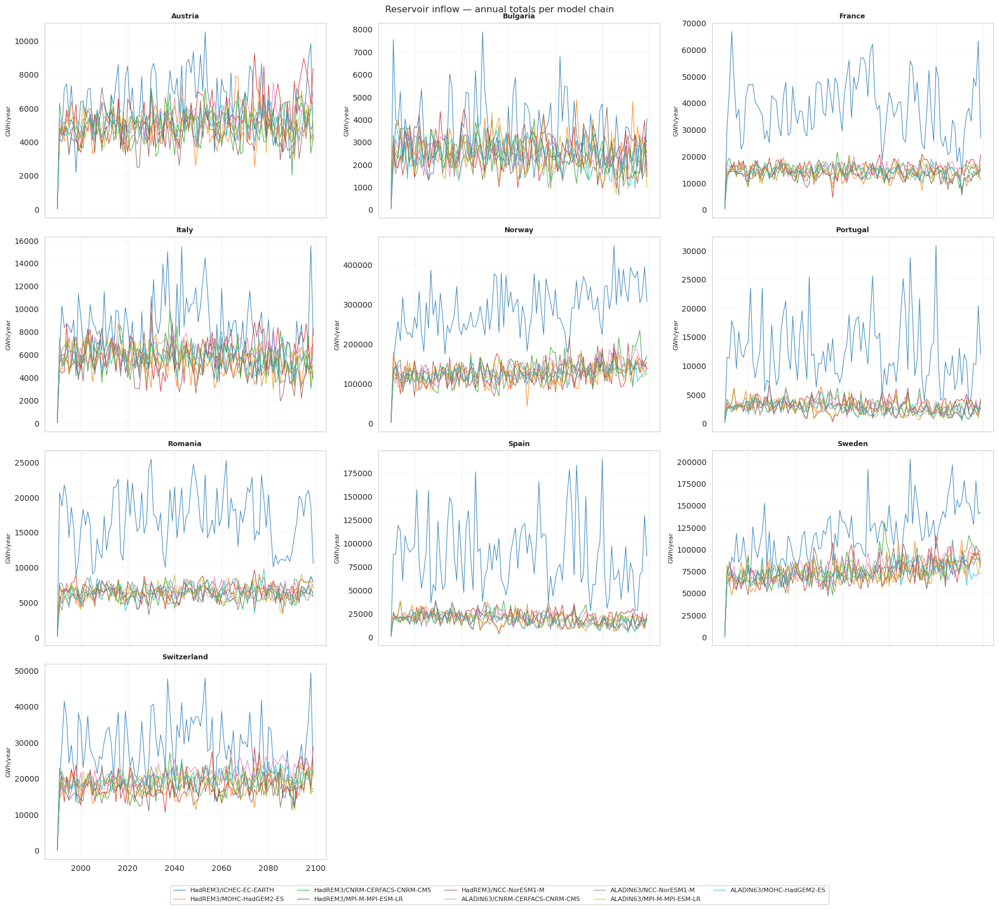

In [28]:
plot_per_model(inflow_annual, inflow_countries, "Reservoir inflow")

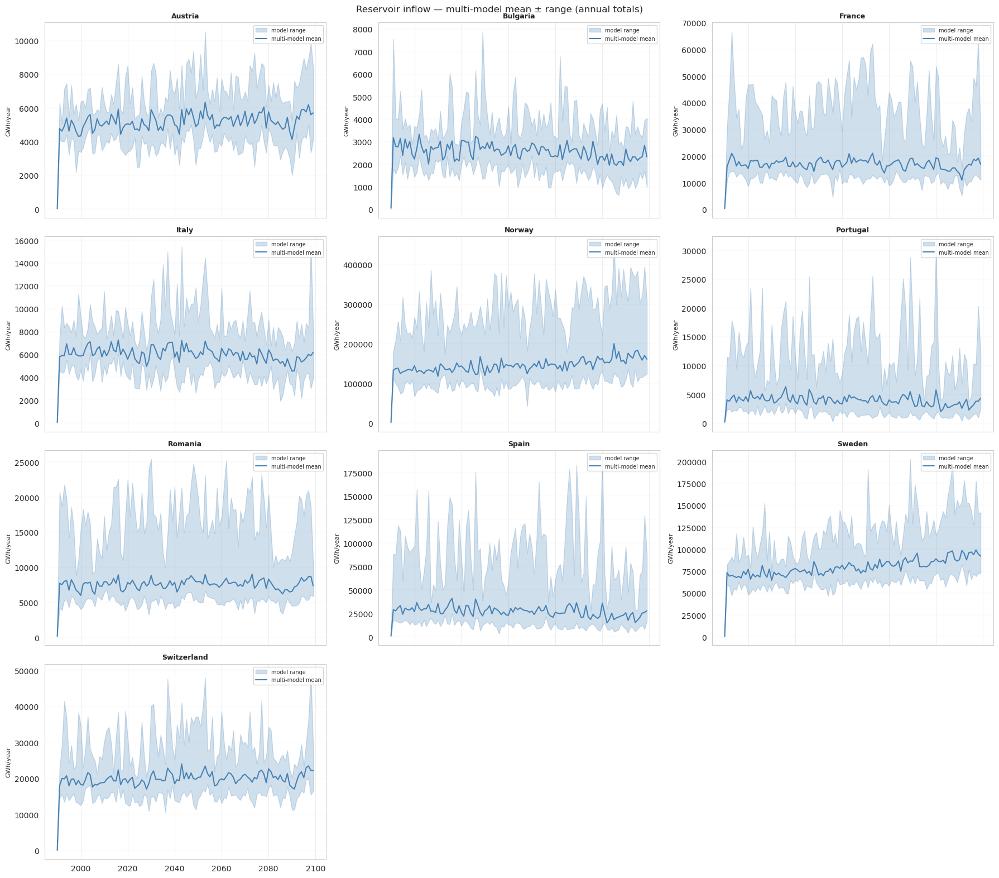

In [29]:
plot_multimodel(inflow_annual, inflow_countries, "Reservoir inflow")

# Heating and cooling demand

## One chain

In [7]:
df_old = pd.read_csv(
    "/net/xenon/climphys/lbloin/CESM2energy/output/CORDEX_data/CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5/output_variables/heating-demand_CORDEX_85.csv"
)
df_new = pd.read_csv(
    "/net/exo/landclim/yhaddad/clim2energy-ch/c2e/outputs/CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5/output_variables/heating-demand_CORDEX_CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_85.csv"
)

In [8]:
df_old

,country,1991-01-01 00:00:00,1991-01-01 03:00:00,1991-01-01 06:00:00,1991-01-01 09:00:00,1991-01-01 12:00:00,1991-01-01 15:00:00,1991-01-01 18:00:00,1991-01-01 21:00:00,1991-01-02 00:00:00,...,2052-12-30 18:00:00,2052-12-30 21:00:00,2052-12-31 00:00:00,2052-12-31 03:00:00,2052-12-31 06:00:00,2052-12-31 09:00:00,2052-12-31 12:00:00,2052-12-31 15:00:00,2052-12-31 18:00:00,2052-12-31 21:00:00
0,Albania,0.281646,0.294970,0.320285,0.326330,0.292138,0.268908,0.306449,0.278763,0.283391,...,0.174402,0.164582,0.174202,0.179185,0.193048,0.196837,0.177640,0.165885,0.192845,0.179809
1,Austria,1.489595,1.461888,1.508368,1.478622,1.288002,1.165648,1.318696,1.201567,1.233843,...,0.901244,0.859651,0.919548,0.955678,1.040035,1.070855,0.975553,0.919246,1.077839,1.013138
2,Belgium,0.705282,0.636633,0.614369,0.575355,0.490614,0.445842,0.518788,0.496289,0.543495,...,0.215009,0.179042,0.172310,0.168899,0.184218,0.202801,0.209099,0.232455,0.329748,0.379453
3,Bosnia and Herzegovina,0.485588,0.485933,0.509570,0.506023,0.445087,0.405450,0.460284,0.419628,0.429945,...,0.339543,0.323016,0.344416,0.356589,0.386347,0.395766,0.358445,0.335527,0.390486,0.363979
4,Bulgaria,1.671406,1.751441,1.908873,1.957489,1.767979,1.645462,1.899847,1.754269,1.813508,...,1.297532,1.243614,1.336834,1.396346,1.527345,1.580702,1.447492,1.371056,1.616012,1.526978
5,Croatia,0.507855,0.502814,0.522516,0.515001,0.450270,0.408297,0.462017,0.420378,0.430366,...,0.302970,0.290596,0.312789,0.327356,0.359037,0.372887,0.342966,0.326593,0.387392,0.368771
6,Czech Republic,1.747533,1.707822,1.755518,1.715260,1.489953,1.345279,1.519069,1.382147,1.417774,...,1.241529,1.183700,1.263586,1.308152,1.415190,1.445151,1.302346,1.210438,1.395362,1.284767
7,Denmark,0.672093,0.679032,0.721833,0.729293,0.654718,0.610371,0.710682,0.665620,0.701408,...,0.592238,0.554960,0.582699,0.593956,0.633432,0.638579,0.569075,0.524036,0.599843,0.549802
8,Estonia,0.228531,0.233960,0.251202,0.255590,0.230465,0.215299,0.250698,0.234422,0.246289,...,0.314931,0.296000,0.312910,0.322352,0.348784,0.358147,0.326398,0.308639,0.364301,0.345809
9,Finland,2.536015,2.557216,2.709413,2.725324,2.433785,2.255724,2.610384,2.429865,2.545396,...,4.413502,4.096567,4.251116,4.270161,4.471087,4.404993,3.814392,3.388705,3.708569,3.212515


In [9]:
# Reshape from wide to long (dates as columns → dates as index)
def wide_to_long(df):
    # Support both: DataFrame with 'country' column, or DataFrame already indexed by country
    if "country" in df.columns:
        df = df.set_index("country")
    df = df.T
    df.index = pd.to_datetime(df.index)
    df.index.name = "time"
    return df


ts_old = wide_to_long(df_old)
ts_new = wide_to_long(df_new)

print("OLD:", ts_old.index.min(), "→", ts_old.index.max(), f"({len(ts_old)} steps)")
print("NEW:", ts_new.index.min(), "→", ts_new.index.max(), f"({len(ts_new)} steps)")

OLD: 1991-01-01 00:00:00 → 2052-12-31 21:00:00 (181040 steps)
NEW: 1991-01-01 00:00:00 → 2100-12-31 21:00:00 (321200 steps)


In [10]:
# Find common timeframe and align
common_idx = ts_old.index.intersection(ts_new.index)
common_countries = ts_old.columns.intersection(ts_new.columns)

ts_old_c = ts_old.loc[common_idx, common_countries]
ts_new_c = ts_new.loc[common_idx, common_countries]

print(
    f"Common period : {common_idx.min().date()} → {common_idx.max().date()}  ({len(common_idx)} days)"
)
print(f"Common countries ({len(common_countries)}): {common_countries.tolist()}")

Common period : 1991-01-01 → 2052-12-31  (181040 days)
Common countries (32): ['Albania', 'Austria', 'Belgium', 'Bosnia and Herzegovina', 'Bulgaria', 'Croatia', 'Czech Republic', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Ireland', 'Italy', 'Latvia', 'Lithuania', 'Macedonia', 'Montenegro', 'Netherlands', 'Norway', 'Poland', 'Portugal', 'Romania', 'Serbia', 'Slovakia', 'Slovenia', 'Spain', 'Sweden', 'Switzerland', 'United Kingdom']


In [11]:
# Summary statistics comparison over the common period
diff = ts_new_c - ts_old_c

stats = pd.DataFrame(
    {
        "old_mean": ts_old_c.mean(),
        "new_mean": ts_new_c.mean(),
        "bias": diff.mean(),
        "rmse": np.sqrt((diff**2).mean()),
        "corr": ts_old_c.corrwith(ts_new_c),
    }
).round(4)

print(stats.to_string())

                        old_mean  new_mean    bias    rmse  corr
country                                                         
Albania                   0.0609    0.0609  0.0000  0.0004   1.0
Austria                   0.4314    0.4314  0.0000  0.0013   1.0
Belgium                   0.3595    0.3595  0.0000  0.0011   1.0
Bosnia and Herzegovina    0.1408    0.1408  0.0000  0.0008   1.0
Bulgaria                  0.4959    0.4959  0.0000  0.0013   1.0
Croatia                   0.1265    0.1265  0.0000  0.0007   1.0
Czech Republic            0.5752    0.5752  0.0000  0.0015   1.0
Denmark                   0.2112    0.2112  0.0000  0.0010   1.0
Estonia                   0.1116    0.1116  0.0000  0.0003   1.0
Finland                   1.1731    1.1983  0.0252  0.0359   1.0
France                    6.5620    6.5620  0.0001  0.0251   1.0
Germany                   1.7094    1.7094  0.0001  0.0060   1.0
Greece                    0.2540    0.2541  0.0000  0.0033   1.0
Hungary                  

## All chains — Demand analysis

Three demand variables loaded for all 9 model chains (1991–2100, RCP8.5):
- **Heating demand** (conventional, with current fuel mix)
- **Heating demand — fully electrified** (assuming full electrification of heat)
- **Cooling demand**

Analysis includes:
1. Annual time-series per model chain
2. Multi-model mean ± spread (annual totals)
3. Period bar plots: reference (1991–2020), mid-century (2041–2070), end-of-century (2071–2100)
4. Climate change signal vs. reference
5. Seasonal cycle by period

In [12]:
# ── Demand variable definitions ─────────────────────────────────────────────
NEW_BASE = Path("/net/exo/landclim/yhaddad/clim2energy-ch/c2e/outputs")

DEMAND_VARS = {
    "heating": "heating-demand_CORDEX_{chain}_85.csv",
    "heating_elec": "heating-demand_CORDEX_{chain}_85_fully-electrified.csv",
    "cooling": "cooling-demand_CORDEX_{chain}_85.csv",
}
DEMAND_LABELS = {
    "heating": "Heating demand (conventional)",
    "heating_elec": "Heating demand (fully electrified)",
    "cooling": "Cooling demand",
}

# Climate periods for comparison
DEMAND_PERIODS = {
    "reference": (1991, 2020),
    "mid-century": (2041, 2070),
    "end-of-century": (2071, 2100),
}
PERIOD_COLORS = {
    "reference": "#4C72B0",
    "mid-century": "#DD8452",
    "end-of-century": "#55A868",
}

# Representative countries for time-series / seasonal plots (3×3 grid)
DEMAND_KEY_COUNTRIES = [
    "Switzerland",
    "Germany",
    "France",
    "Italy",
    "Spain",
    "United Kingdom",
    "Sweden",
    "Poland",
    "Greece",
]

# ── Load all chains ──────────────────────────────────────────────────────────
# demand_annual[var][chain]  → DataFrame(year × country)
# demand_seasonal[var][chain][period] → DataFrame(month × country)
demand_annual = {var: {} for var in DEMAND_VARS}
demand_seasonal = {var: {} for var in DEMAND_VARS}

for chain in all_chains:
    for var, fname_tpl in DEMAND_VARS.items():
        p = NEW_BASE / chain / "output_variables" / fname_tpl.format(chain=chain)
        if not p.exists():
            print(f"  MISSING: {p.name}")
            continue
        ts = wide_to_long(pd.read_csv(p))
        # Annual sums (3-hourly → yearly totals in the same unit)
        demand_annual[var][chain] = ts.groupby(ts.index.year).sum()
        # Monthly mean per climate period (for seasonal cycle)
        demand_seasonal[var][chain] = {}
        for period_name, (yr_start, yr_end) in DEMAND_PERIODS.items():
            mask = (ts.index.year >= yr_start) & (ts.index.year <= yr_end)
            ts_p = ts.loc[mask]
            demand_seasonal[var][chain][period_name] = ts_p.groupby(
                ts_p.index.month
            ).mean()
    print(f"  Loaded {chain}")

demand_countries = sorted(demand_annual["heating"][all_chains[0]].columns.tolist())
print(f"\nAll {len(demand_annual['heating'])} chains loaded.")
print(f"Countries ({len(demand_countries)}): {demand_countries}")

  Loaded MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH
  Loaded MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES
  Loaded MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5
  Loaded MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR
  Loaded MOHC-HadREM3-GA7-05_NCC-NorESM1-M
  Loaded CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5
  Loaded CNRM-ALADIN63_NCC-NorESM1-M
  Loaded CNRM-ALADIN63_MPI-M-MPI-ESM-LR
  Loaded CNRM-ALADIN63_MOHC-HadGEM2-ES

All 9 chains loaded.
Countries (35): ['Albania', 'Austria', 'Belgium', 'Bosnia and Herzegovina', 'Bulgaria', 'Croatia', 'Czech Republic', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Ireland', 'Italy', 'Kosovo', 'Latvia', 'Lithuania', 'Luxembourg', 'Macedonia', 'Montenegro', 'Netherlands', 'Norway', 'Poland', 'Portugal', 'Romania', 'Serbia', 'Slovakia', 'Slovenia', 'Spain', 'Sweden', 'Switzerland', 'Ukraine', 'United Kingdom']


In [13]:
# Mean annual demand — country (rows) × model chain (columns)
# Values are the mean annual total over the full simulation period (1991–2100)
for var, label in DEMAND_LABELS.items():
    table = pd.DataFrame(
        {
            CHAIN_LABELS[chain]: demand_annual[var][chain].mean()
            for chain in all_chains
            if chain in demand_annual[var]
        }
    ).round(1)
    table.index.name = "Country"
    table.columns.name = "Chain"

    styled = (
        table.style.background_gradient(
            cmap="YlOrRd", axis=1
        )  # colour scale across chains, per row
        .format("{:.0f}")
        .set_caption(f"{label} — mean annual total (GWh/year), 1991–2100")
        .set_table_styles(
            [
                {
                    "selector": "caption",
                    "props": [
                        ("font-weight", "bold"),
                        ("font-size", "13px"),
                        ("text-align", "left"),
                    ],
                },
                {
                    "selector": "th",
                    "props": [("font-size", "10px"), ("text-align", "center")],
                },
                {
                    "selector": "td",
                    "props": [
                        ("font-size", "10px"),
                        ("text-align", "right"),
                        ("padding", "2px 6px"),
                    ],
                },
            ]
        )
    )
    display(styled)

Chain,HadREM3/ICHEC-EC-EARTH,HadREM3/MOHC-HadGEM2-ES,HadREM3/CNRM-CERFACS-CNRM-CM5,HadREM3/MPI-M-MPI-ESM-LR,HadREM3/NCC-NorESM1-M,ALADIN63/CNRM-CERFACS-CNRM-CM5,ALADIN63/NCC-NorESM1-M,ALADIN63/MPI-M-MPI-ESM-LR,ALADIN63/MOHC-HadGEM2-ES
Country,,,,,,,,,
Albania,151,148,150,154,154,151,153,157,146
Austria,1109,1080,1107,1136,1128,1090,1133,1146,1080
Belgium,908,870,893,941,916,893,913,944,882
Bosnia and Herzegovina,365,362,365,371,374,361,375,374,358
Bulgaria,1274,1273,1279,1306,1298,1271,1296,1306,1249
Croatia,322,316,322,329,327,318,329,334,316
Czech Republic,1511,1481,1514,1546,1525,1506,1537,1562,1477
Denmark,528,508,537,545,535,534,535,545,509
Estonia,286,279,286,287,289,288,290,286,280


Chain,HadREM3/ICHEC-EC-EARTH,HadREM3/MOHC-HadGEM2-ES,HadREM3/CNRM-CERFACS-CNRM-CM5,HadREM3/MPI-M-MPI-ESM-LR,HadREM3/NCC-NorESM1-M,ALADIN63/CNRM-CERFACS-CNRM-CM5,ALADIN63/NCC-NorESM1-M,ALADIN63/MPI-M-MPI-ESM-LR,ALADIN63/MOHC-HadGEM2-ES
Country,,,,,,,,,
Albania,9404,9215,9327,9539,9536,9374,9512,9731,9074
Austria,18452,17973,18418,18894,18766,18135,18850,19074,17970
Belgium,11294,10824,11116,11710,11395,11109,11358,11743,10976
Bosnia and Herzegovina,5121,5071,5116,5206,5238,5057,5255,5242,5018
Bulgaria,9157,9143,9192,9380,9325,9134,9309,9381,8971
Croatia,6732,6592,6732,6874,6831,6655,6884,6968,6614
Czech Republic,17682,17332,17713,18094,17843,17621,17988,18276,17285
Denmark,20417,19624,20774,21082,20692,20644,20680,21075,19679
Estonia,2737,2664,2730,2738,2764,2746,2770,2736,2675


Chain,HadREM3/ICHEC-EC-EARTH,HadREM3/MOHC-HadGEM2-ES,HadREM3/CNRM-CERFACS-CNRM-CM5,HadREM3/MPI-M-MPI-ESM-LR,HadREM3/NCC-NorESM1-M,ALADIN63/CNRM-CERFACS-CNRM-CM5,ALADIN63/NCC-NorESM1-M,ALADIN63/MPI-M-MPI-ESM-LR,ALADIN63/MOHC-HadGEM2-ES
Country,,,,,,,,,
Albania,66,81,67,66,69,62,66,67,76
Austria,16,24,12,9,19,9,14,10,12
Belgium,10,17,8,8,19,8,18,8,12
Bosnia and Herzegovina,40,50,43,32,40,30,31,33,37
Bulgaria,103,124,111,102,111,101,104,97,115
Croatia,77,86,73,66,78,61,67,65,70
Czech Republic,0,0,0,0,0,0,0,0,0
Denmark,6,10,5,4,9,4,8,4,6
Estonia,0,0,0,0,0,0,0,0,0


### Annual totals — per model chain

Each panel shows one of the 9 key countries; each line is one model chain.

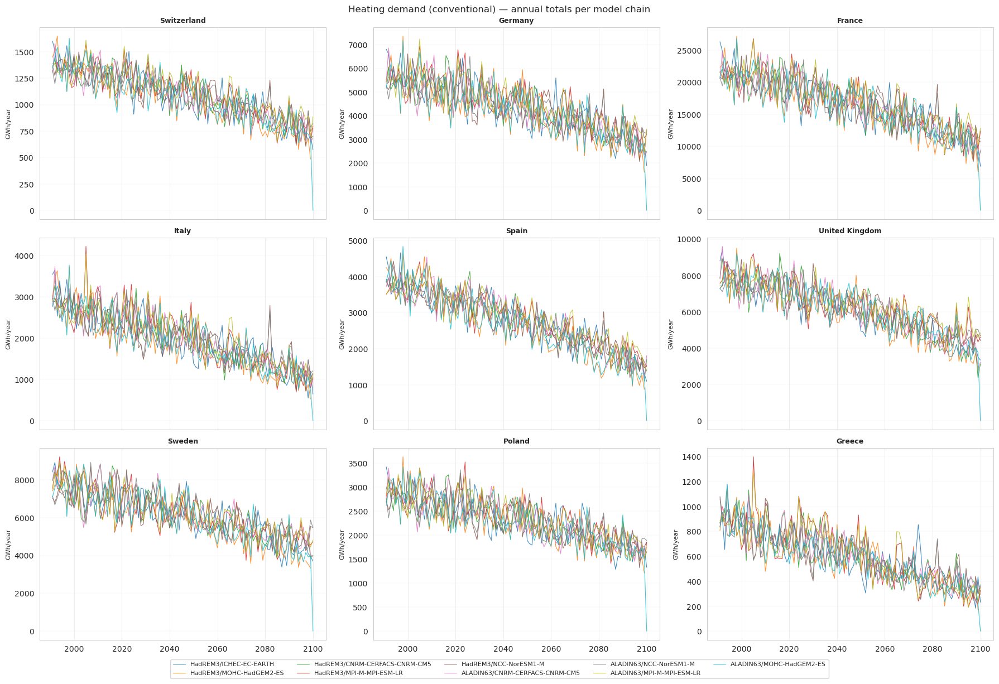

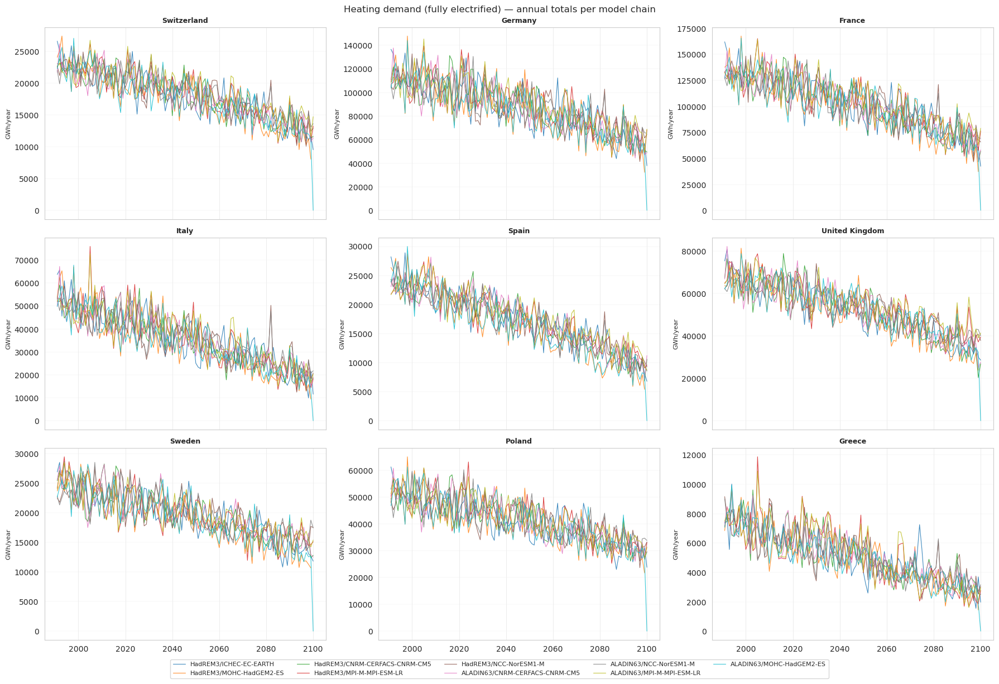

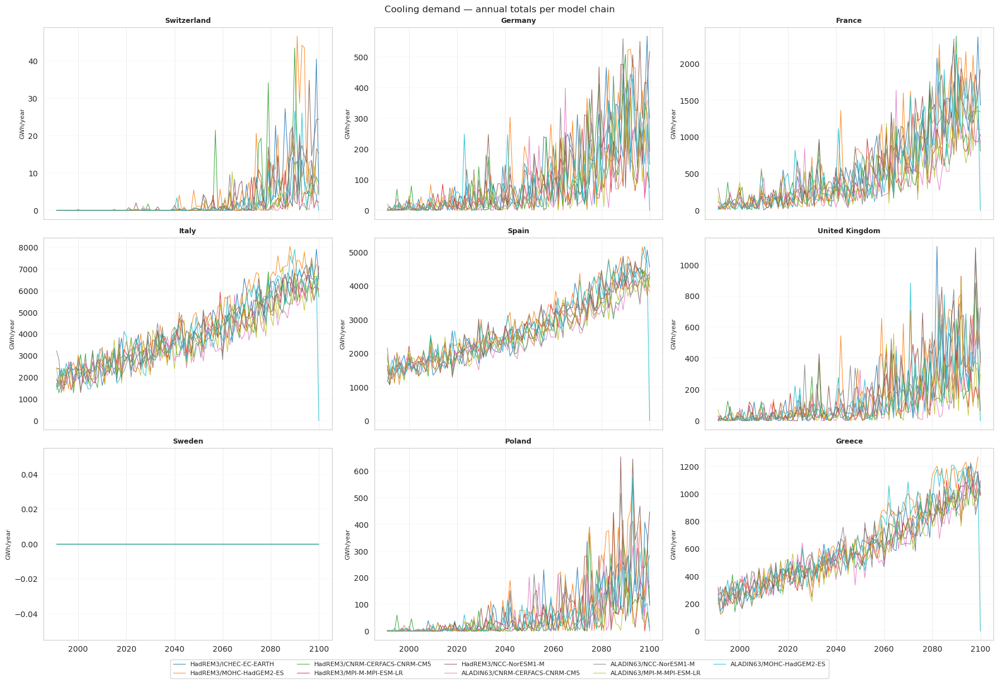

In [15]:
for var in DEMAND_VARS:
    plot_per_model(
        demand_annual[var], DEMAND_KEY_COUNTRIES, DEMAND_LABELS[var], unit="GWh/year"
    )

### Annual totals — multi-model mean and spread

Shaded band shows the full model range (min–max across chains); thick line is the multi-model mean.

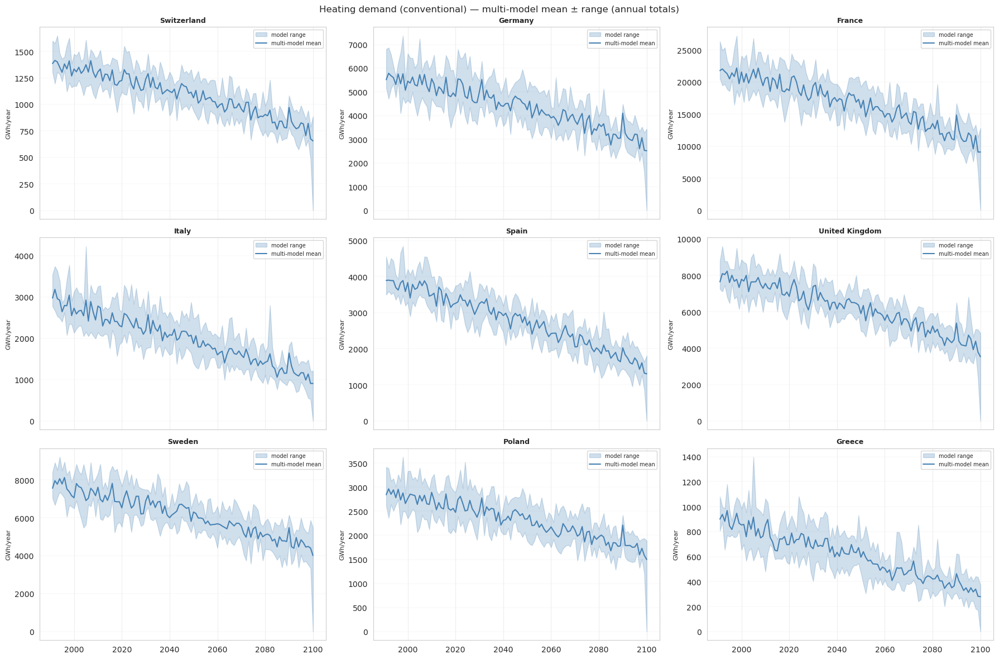

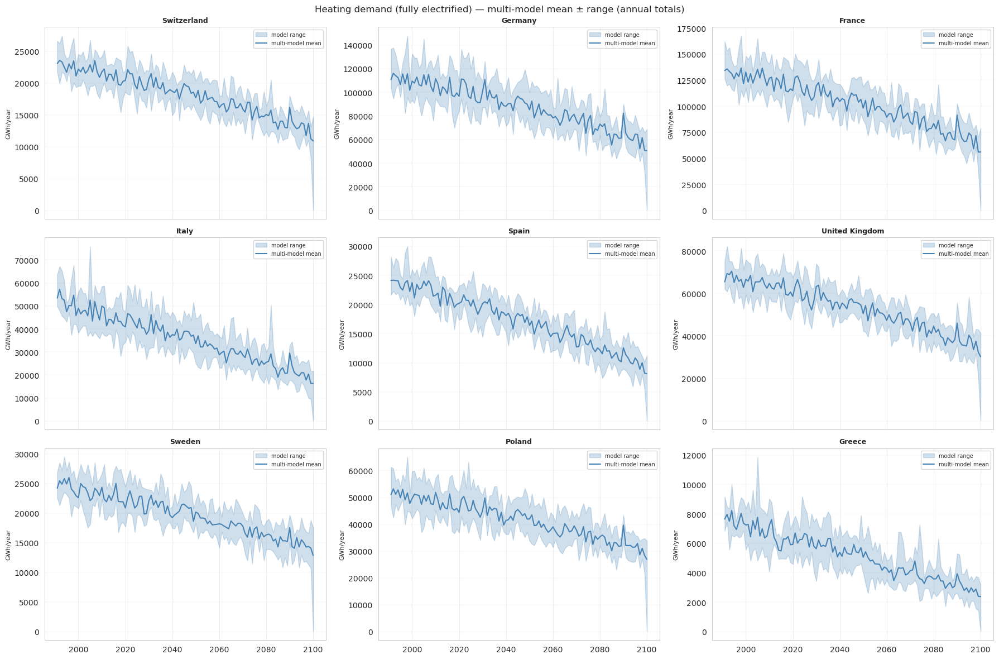

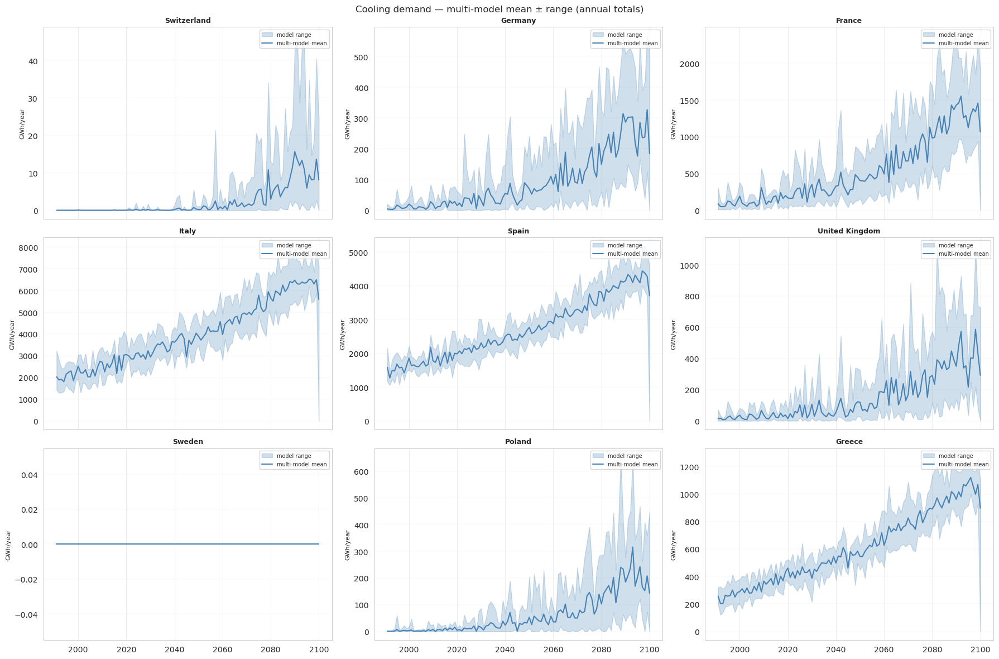

In [16]:
for var in DEMAND_VARS:
    plot_multimodel(
        demand_annual[var], DEMAND_KEY_COUNTRIES, DEMAND_LABELS[var], unit="GWh/year"
    )

### Mean annual totals by climate period

Grouped bars: multi-model mean per period with ±1 std error bars.
All 35 countries shown; error bars reflect inter-model spread.

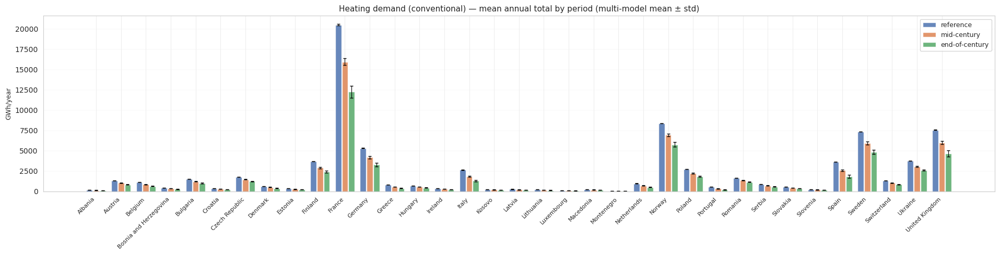

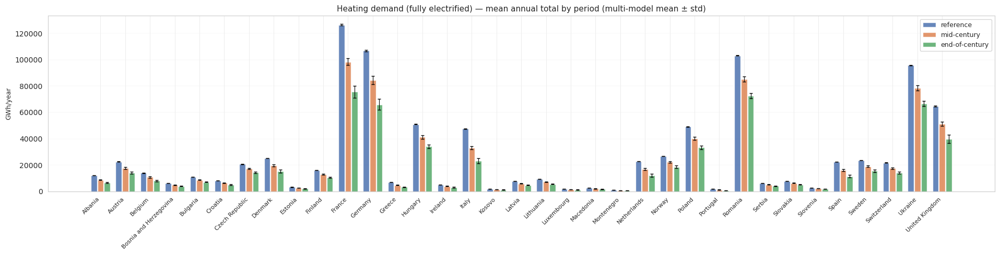

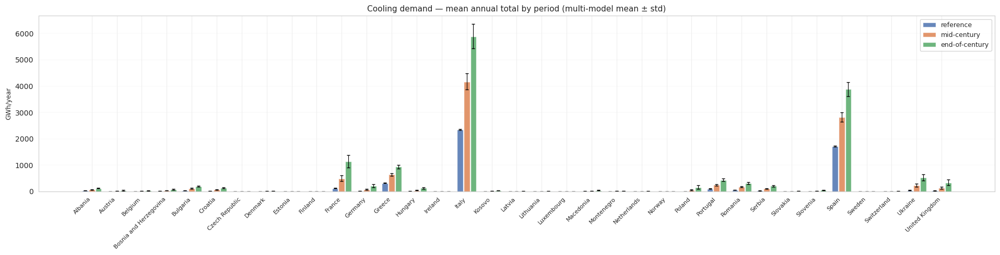

In [17]:
def plot_period_bars(ann_data, countries, variable_label, unit="GWh/year"):
    """Grouped bar chart: multi-model mean annual total per period, ±1 std error bars."""
    n_periods = len(DEMAND_PERIODS)
    n_countries = len(countries)
    x = np.arange(n_countries)
    width = 0.8 / n_periods

    fig, ax = plt.subplots(figsize=(max(14, n_countries * 0.55), 5))

    for i, (period_name, (yr_start, yr_end)) in enumerate(DEMAND_PERIODS.items()):
        chain_means = []
        for chain in all_chains:
            if chain not in ann_data:
                continue
            df = ann_data[chain]
            mask = (df.index >= yr_start) & (df.index <= yr_end)
            chain_means.append(df.loc[mask, countries].mean())
        if not chain_means:
            continue

        stacked = pd.DataFrame(chain_means)  # shape: (n_chains × n_countries)
        mm_mean = stacked.mean()
        mm_std = stacked.std()

        ax.bar(
            x + i * width,
            mm_mean.values,
            width=width * 0.92,
            label=period_name,
            color=PERIOD_COLORS[period_name],
            alpha=0.85,
        )
        ax.errorbar(
            x + i * width,
            mm_mean.values,
            yerr=mm_std.values,
            fmt="none",
            color="k",
            capsize=2,
            linewidth=0.8,
        )

    ax.set_xticks(x + width * (n_periods - 1) / 2)
    ax.set_xticklabels(countries, rotation=45, ha="right", fontsize=8)
    ax.set_ylabel(unit, fontsize=9)
    ax.set_title(
        f"{variable_label} — mean annual total by period (multi-model mean ± std)",
        fontsize=11,
    )
    ax.legend(fontsize=9)
    ax.yaxis.grid(True, linewidth=0.3)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()


for var in DEMAND_VARS:
    plot_period_bars(demand_annual[var], demand_countries, DEMAND_LABELS[var])

### Climate change signal (vs. reference 1991–2020)

Left: absolute change in annual total. Right: relative change (%). Both show multi-model mean ± std.
Negative values = demand reduction; positive = demand increase.

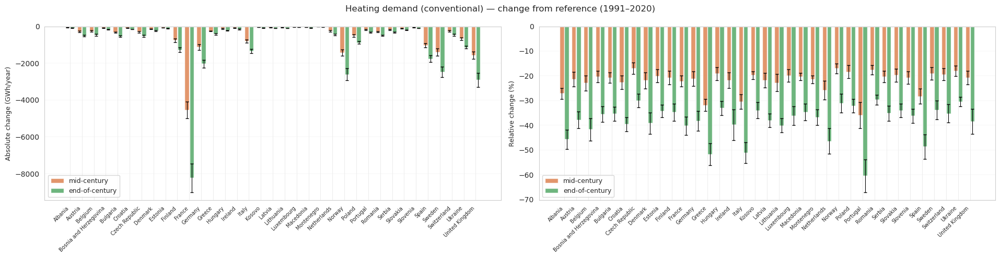

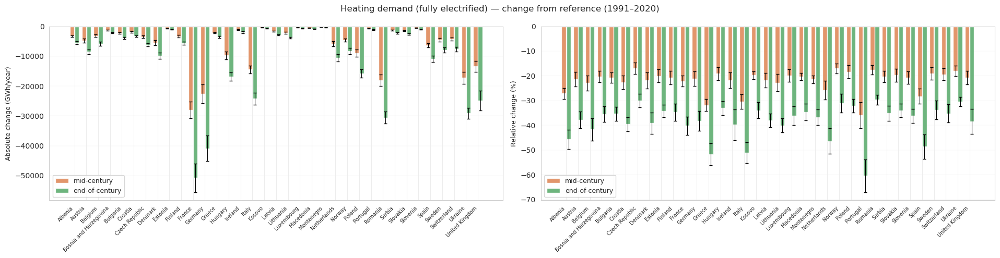

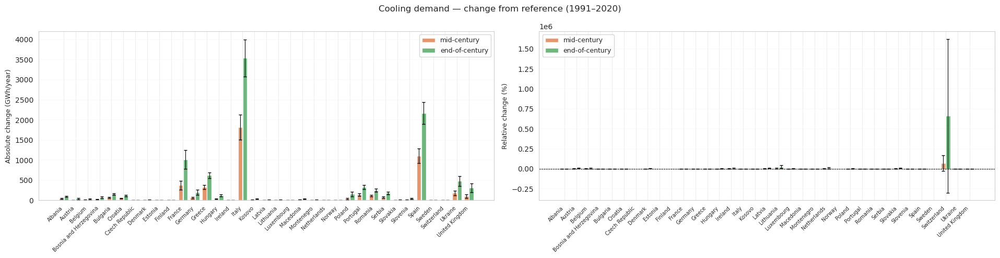

In [18]:
def plot_change_signal(ann_data, countries, variable_label, unit="GWh/year"):
    """Absolute and % change from reference to future periods, multi-model mean ± std."""
    ref_start, ref_end = DEMAND_PERIODS["reference"]
    future_periods = {k: v for k, v in DEMAND_PERIODS.items() if k != "reference"}

    n_countries = len(countries)
    n_future = len(future_periods)
    x = np.arange(n_countries)
    width = 0.8 / n_future

    fig, axes = plt.subplots(1, 2, figsize=(max(18, n_countries * 0.55), 5))
    ax_abs, ax_pct = axes

    for i, (period_name, (yr_start, yr_end)) in enumerate(future_periods.items()):
        color = list(PERIOD_COLORS.values())[i + 1]
        abs_changes, pct_changes = [], []

        for chain in all_chains:
            if chain not in ann_data:
                continue
            df = ann_data[chain]
            ref = df.loc[
                (df.index >= ref_start) & (df.index <= ref_end), countries
            ].mean()
            fut = df.loc[
                (df.index >= yr_start) & (df.index <= yr_end), countries
            ].mean()
            abs_changes.append(fut - ref)
            pct_changes.append(((fut - ref) / ref.replace(0, np.nan)) * 100)

        for ax, changes, ylabel in zip(
            [ax_abs, ax_pct],
            [abs_changes, pct_changes],
            [f"Absolute change ({unit})", "Relative change (%)"],
        ):
            df_vals = pd.DataFrame(changes)
            mm_mean = df_vals.mean()
            mm_std = df_vals.std()

            ax.bar(
                x + i * width,
                mm_mean.values,
                width=width * 0.92,
                label=period_name,
                color=color,
                alpha=0.85,
            )
            ax.errorbar(
                x + i * width,
                mm_mean.values,
                yerr=mm_std.values,
                fmt="none",
                color="k",
                capsize=2,
                linewidth=0.8,
            )
            ax.axhline(0, color="k", linewidth=0.6, linestyle="--")
            ax.set_ylabel(ylabel, fontsize=9)
            ax.legend(fontsize=9)
            ax.yaxis.grid(True, linewidth=0.3)
            ax.set_axisbelow(True)

    for ax in axes:
        ax.set_xticks(x + width * (n_future - 1) / 2)
        ax.set_xticklabels(countries, rotation=45, ha="right", fontsize=7)

    fig.suptitle(f"{variable_label} — change from reference (1991–2020)", fontsize=12)
    plt.tight_layout()
    plt.show()


for var in DEMAND_VARS:
    plot_change_signal(demand_annual[var], demand_countries, DEMAND_LABELS[var])

### Seasonal cycle by climate period

Monthly mean demand per period for 9 key countries. Shaded band = model range (min–max); line = multi-model mean.
This reveals shifts in the heating/cooling season shape under climate change.

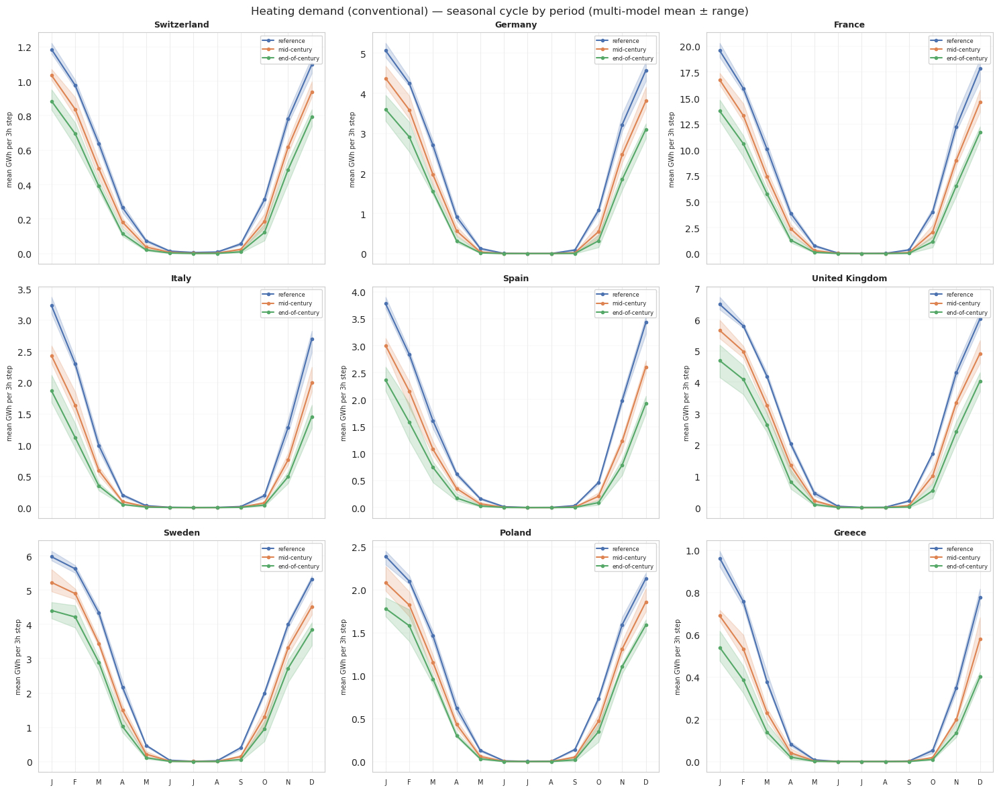

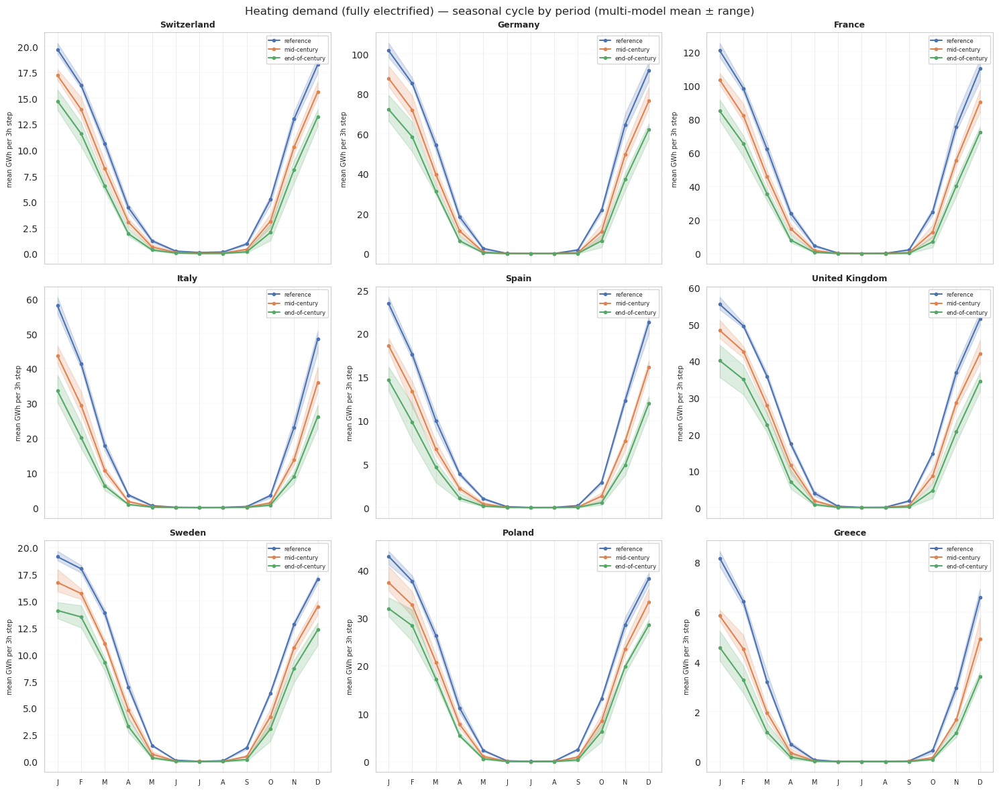

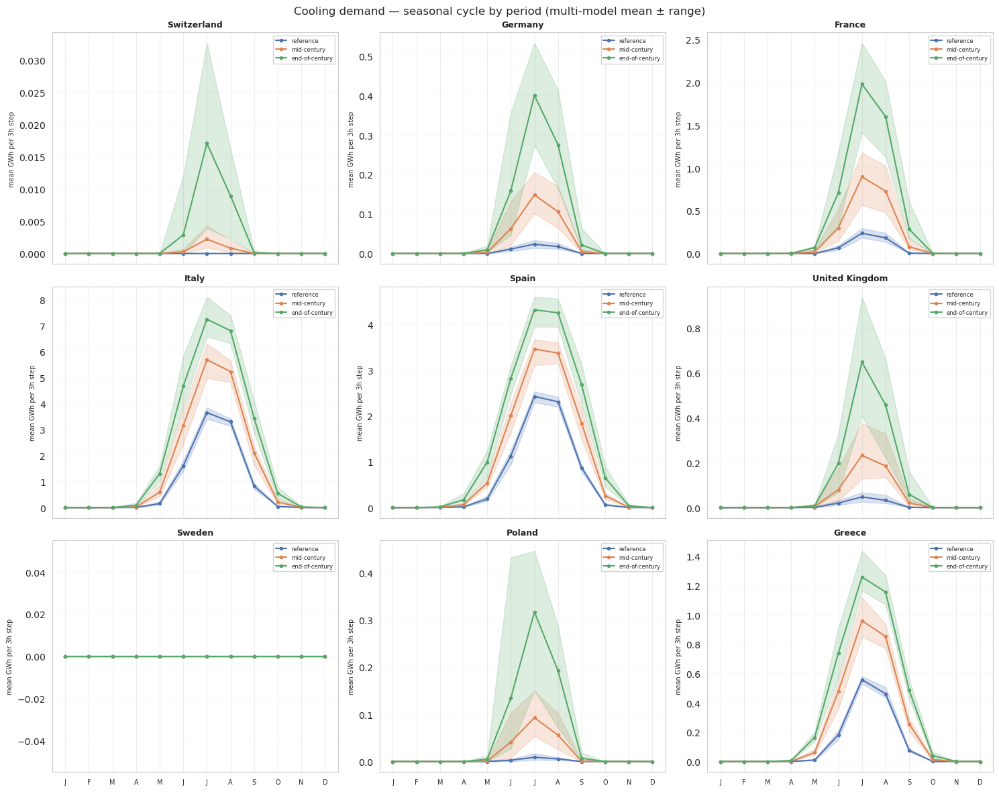

In [19]:
def plot_seasonal_cycle(
    seasonal_data, countries, variable_label, unit="mean GWh per 3h step"
):
    """Monthly mean demand by period for selected countries, multi-model mean ± range."""
    ncols = 3
    nrows = int(np.ceil(len(countries) / ncols))
    month_ticks = list(range(1, 13))
    month_lbls = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]

    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows), sharex=True)
    axes = axes.flatten()

    for ax, country in zip(axes, countries):
        for period_name, color in PERIOD_COLORS.items():
            monthly_chains = []
            for chain in all_chains:
                if chain not in seasonal_data:
                    continue
                if period_name not in seasonal_data[chain]:
                    continue
                df = seasonal_data[chain][period_name]
                if country in df.columns:
                    monthly_chains.append(df[country])
            if not monthly_chains:
                continue

            stacked = pd.DataFrame(monthly_chains).T  # shape: (12 months × n_chains)
            mm_mean = stacked.mean(axis=1)
            mm_min = stacked.min(axis=1)
            mm_max = stacked.max(axis=1)

            ax.fill_between(stacked.index, mm_min, mm_max, alpha=0.2, color=color)
            ax.plot(
                stacked.index,
                mm_mean,
                color=color,
                linewidth=1.5,
                marker="o",
                markersize=3,
                label=period_name,
            )

        ax.set_title(country, fontsize=9, fontweight="bold")
        ax.set_ylabel(unit, fontsize=7)
        ax.set_xticks(month_ticks)
        ax.set_xticklabels(month_lbls, fontsize=7)
        ax.yaxis.grid(True, linewidth=0.3)
        ax.set_axisbelow(True)
        ax.legend(fontsize=6, loc="upper right")

    for ax in axes[len(countries) :]:
        ax.set_visible(False)

    fig.suptitle(
        f"{variable_label} — seasonal cycle by period (multi-model mean ± range)",
        fontsize=12,
    )
    plt.tight_layout()
    plt.show()


for var in DEMAND_VARS:
    plot_seasonal_cycle(demand_seasonal[var], DEMAND_KEY_COUNTRIES, DEMAND_LABELS[var])